# Two routes to causal identification

The two-group, two-period difference-in-differences contrast is:

$$
\widehat\tau_{\mathrm{DID}}
=\left(\overline Y_{1,\mathrm{after}}-\overline Y_{1,\mathrm{before}}\right)
-\left(\overline Y_{0,\mathrm{after}}-\overline Y_{0,\mathrm{before}}\right).
$$

Here, group $1$ is the treated group, group $0$ is the comparison group, $\overline Y_{g,t}$ is the group mean at time $t$, and $\widehat\tau_{\mathrm{DID}}$ subtracts the comparison group's change from the treated group's change.

,Quantity,Value
0,Rows,2500
1,Counties,500
2,First year,2003
3,Last year,2007
4,Treatment cohorts including never treated,4


,Cohort,Counties,Rows,Mean_log_employment
0,Never treated,309,1545,5.630293
1,2004,20,100,6.091561
2,2006,40,200,6.544059
3,2007,131,655,5.823694


Cohort,year,2004,2006,2007,Never treated
0,2003,6.179697,6.573994,5.842906,5.65463
1,2004,6.106564,6.517884,5.810783,5.592
2,2005,6.059452,6.527941,5.820866,5.604808
3,2006,6.026704,6.557435,5.823866,5.638896
4,2007,6.085388,6.543041,5.820048,5.661133


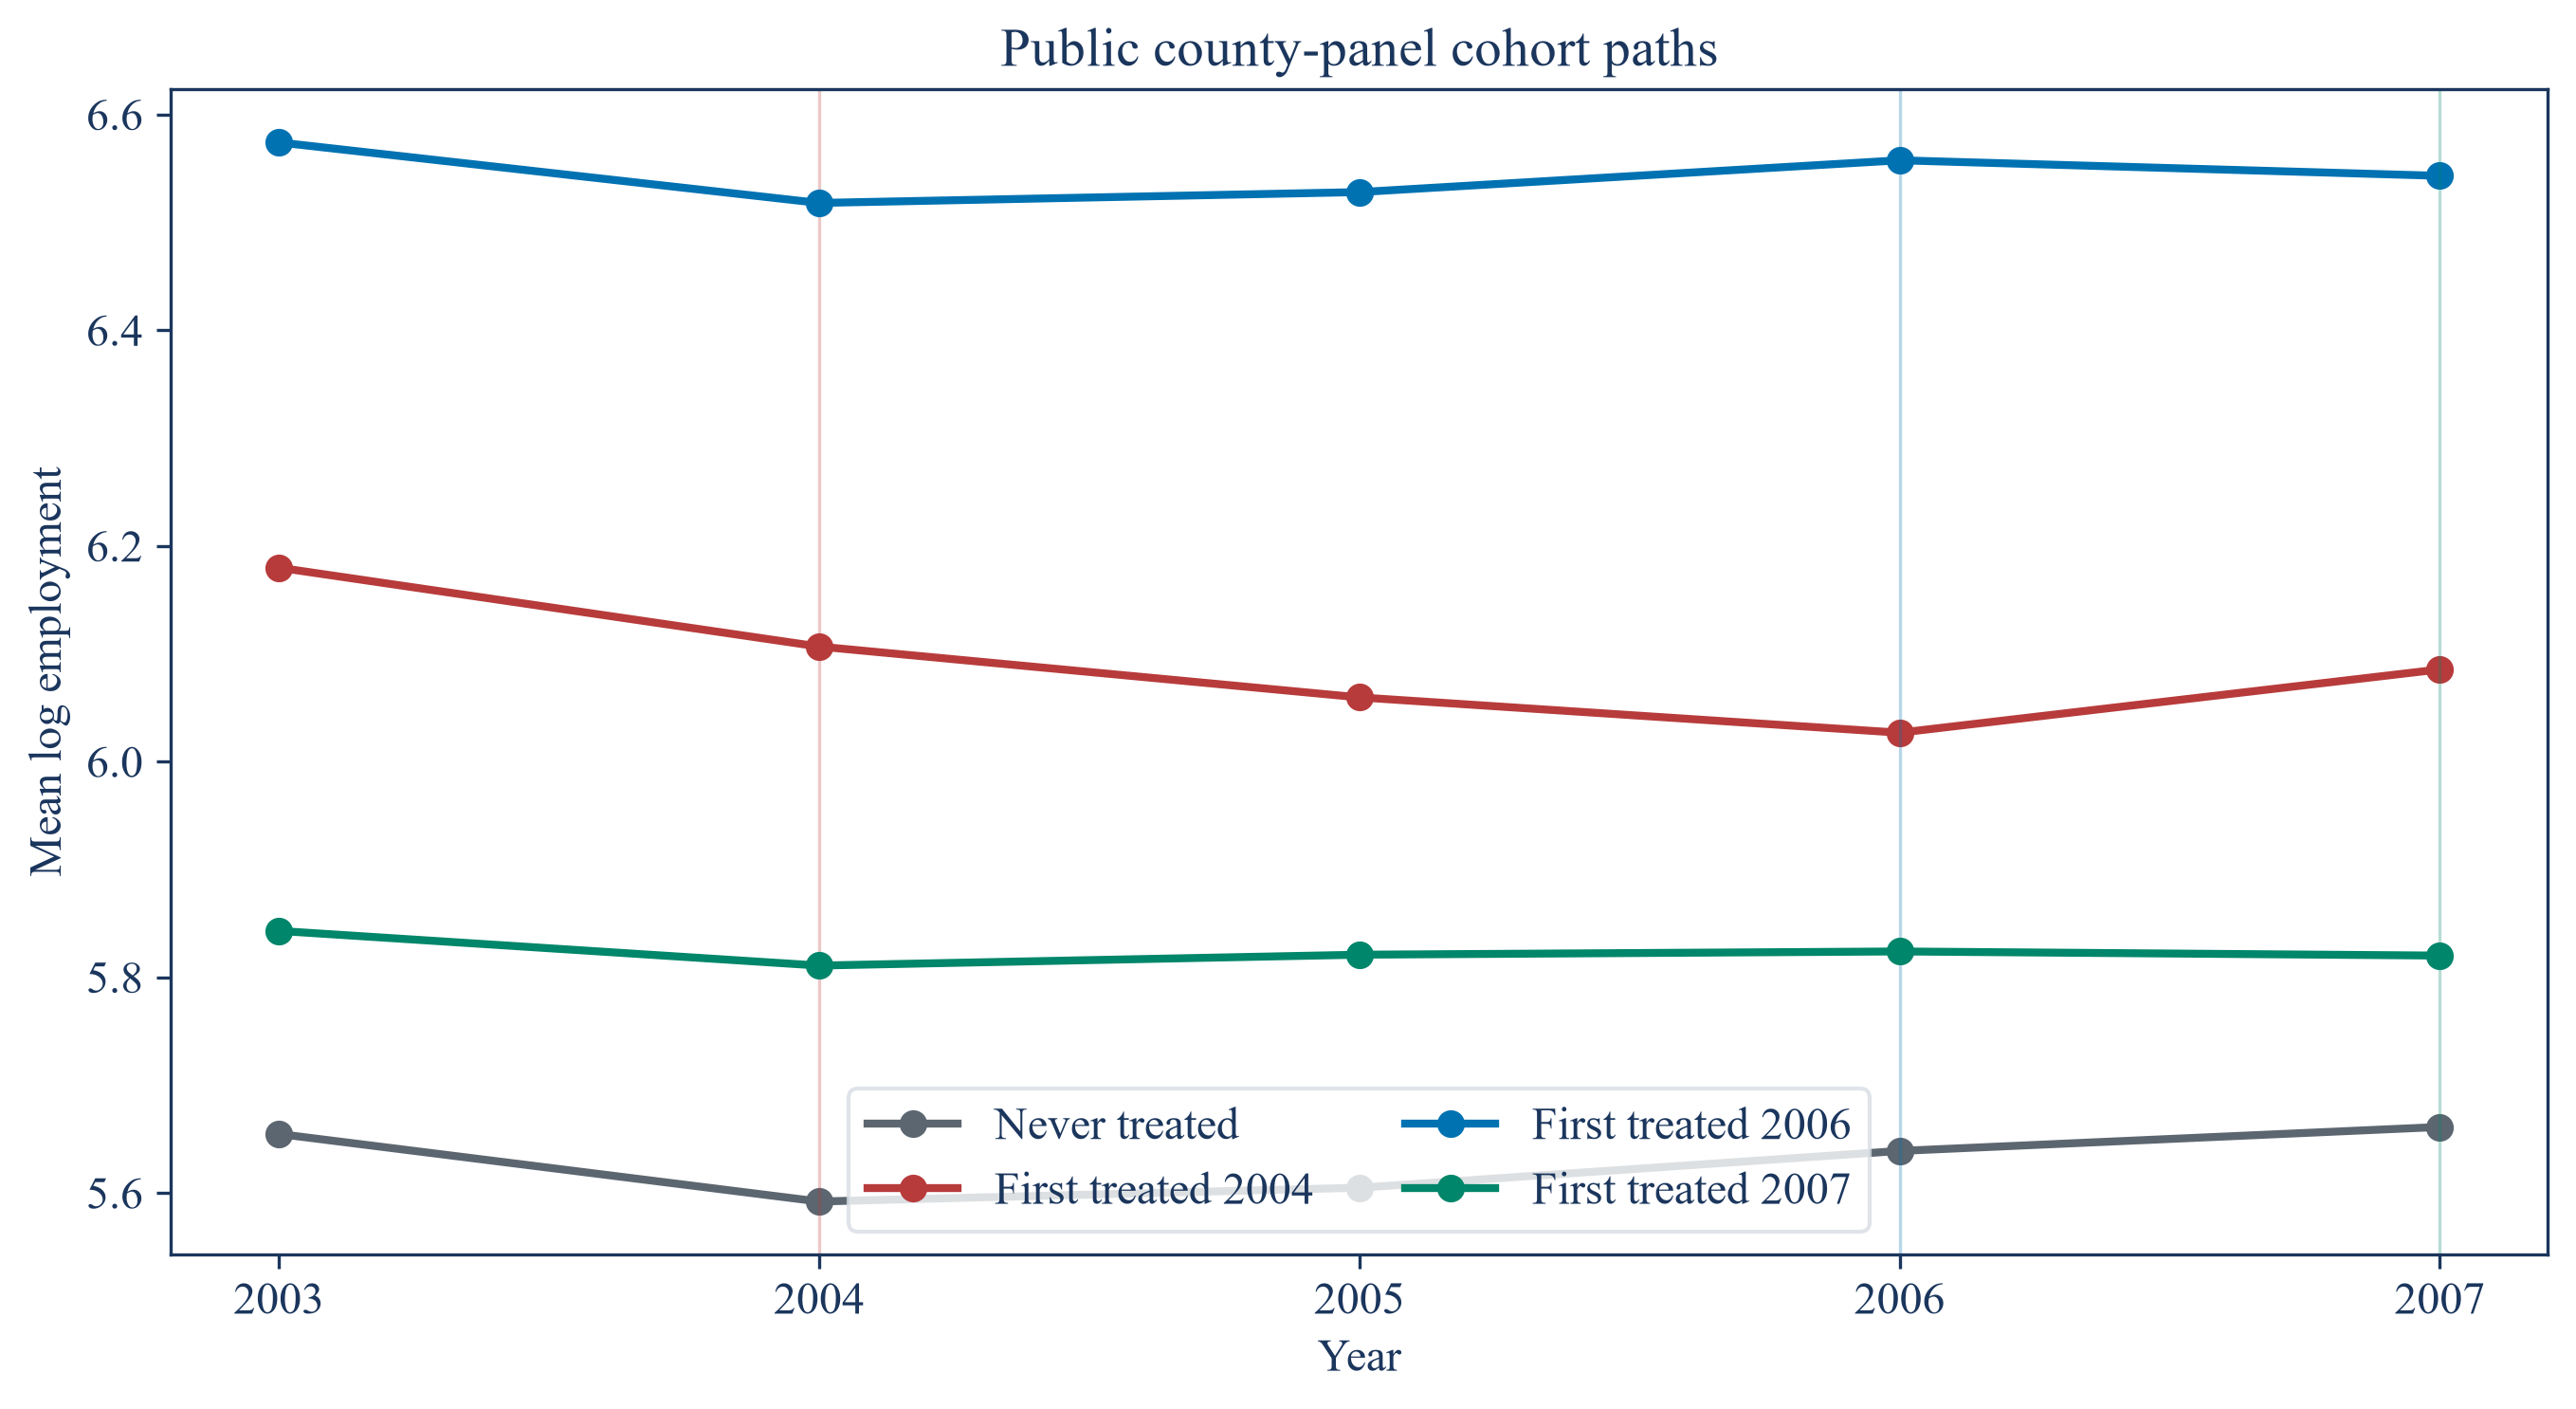

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset

from RiskLabAI.causal_factor_analysis import CausalDAG, DifferenceInDifferencesEstimate, StructuralCausalModelResult, TreatmentEffectDecomposition, average_treatment_effect, backdoor_adjusted_average_treatment_effect, backdoor_adjusted_expectation, difference_in_differences, evaluate_structural_causal_model, frontdoor_adjusted_probability, linear_instrumental_variable_effect, randomized_mean_difference, treatment_effect_decomposition

FIGURES = ROOT / "outputs" / "figures" / "03_structural_treatment_effects"
TABLES = ROOT / "outputs" / "tables" / "03_structural_treatment_effects"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def ols_coefficient(outcome, treatment, controls=None):
    columns = [np.asarray(treatment, dtype=float)]
    if controls is not None:
        values = np.asarray(controls, dtype=float)
        if values.ndim == 1:
            values = values.reshape(-1, 1)
        columns.extend(values[:, index] for index in range(values.shape[1]))
    design = np.column_stack([np.ones(len(outcome))] + columns)
    return float(np.linalg.lstsq(design, np.asarray(outcome, dtype=float), rcond=None)[0][1])

def contract_result(name, action, expected):
    try:
        action()
        return {"Check": name, "Expected result": expected, "Observed result": "Accepted", "Passed": False}
    except Exception as error:
        return {"Check": name, "Expected result": expected, "Observed result": type(error).__name__, "Passed": type(error).__name__ == expected}

def draw_dag(axis, dag, positions, title):
    graph = nx.DiGraph(dag.directed_edges)
    graph.add_nodes_from(dag.nodes)
    nx.draw_networkx_nodes(graph, positions, ax=axis, node_color=palette["cyan"], node_size=1800, edgecolors=palette["text"], linewidths=1.2)
    nx.draw_networkx_labels(graph, positions, ax=axis, font_color=palette["background"], font_weight="bold")
    nx.draw_networkx_edges(graph, positions, ax=axis, edge_color=palette["text"], width=1.8, arrows=True, arrowsize=20)
    axis.set_title(title)
    axis.set_axis_off()

data_path = ensure_dataset(ROOT, "mpdta")
panel = pd.read_csv(data_path)
panel_inventory = pd.DataFrame([
    {"Quantity": "Rows", "Value": len(panel)},
    {"Quantity": "Counties", "Value": panel["countyreal"].nunique()},
    {"Quantity": "First year", "Value": panel["year"].min()},
    {"Quantity": "Last year", "Value": panel["year"].max()},
    {"Quantity": "Treatment cohorts including never treated", "Value": panel["first_treat"].nunique()},
])
cohort_inventory = panel.groupby("first_treat", as_index=False).agg(Counties=("countyreal", "nunique"), Rows=("countyreal", "size"), Mean_log_employment=("lemp", "mean"))
cohort_inventory["Cohort"] = cohort_inventory["first_treat"].replace({0: "Never treated"}).astype(str)
cohort_inventory = cohort_inventory[["Cohort", "Counties", "Rows", "Mean_log_employment"]]
cohort_means = panel.groupby(["year", "first_treat"], as_index=False)["lemp"].mean()
cohort_means["Cohort"] = cohort_means["first_treat"].replace({0: "Never treated"}).astype(str)
cohort_means_table = cohort_means.pivot(index="year", columns="Cohort", values="lemp").reset_index()
save_table(panel_inventory, "mpdta_inventory", "Inventory of the public county panel.", "tab:chapter25-mpdta-inventory")
save_table(cohort_inventory, "mpdta_cohort_inventory", "Treatment-cohort counts in the public county panel.", "tab:chapter25-mpdta-cohorts")
save_table(cohort_means_table, "mpdta_cohort_means", "Mean log employment by year and first-treatment cohort.", "tab:chapter25-mpdta-means")
display(panel_inventory)
display(cohort_inventory)
display(cohort_means_table)

figure, axis = plt.subplots(figsize=(9.2, 5.1))
cohort_colors = {0: palette["muted"], 2004: palette["rose"], 2006: palette["cyan"], 2007: palette["green"]}
for cohort, group in cohort_means.groupby("first_treat"):
    label = "Never treated" if cohort == 0 else f"First treated {cohort}"
    axis.plot(group["year"], group["lemp"], marker="o", linewidth=2, color=cohort_colors[cohort], label=label)
    if cohort != 0:
        axis.axvline(cohort, color=cohort_colors[cohort], linewidth=0.8, alpha=0.28)
axis.set_xlabel("Year")
axis.set_ylabel("Mean log employment")
axis.set_title("Public county-panel cohort paths")
year_values = sorted(panel["year"].unique())
axis.set_xticks(year_values, [str(year) for year in year_values])
axis.legend(ncol=2)
figure.tight_layout()
save_figure(figure, "mpdta_cohort_paths")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## A descriptive public-data contrast

For a group first treated in year $g$, a group-time effect is written as:

$$
\operatorname{ATT}(g,t)
=\mathbb E\!\left[Y_t(1)-Y_t(0)\mid G=g\right].
$$

Here, $G$ is the first treatment year, $g$ is one treatment cohort, $t$ is the outcome year, $Y_t(1)$ is the treated potential outcome at time $t$, $Y_t(0)$ is its untreated counterpart, and $\operatorname{ATT}(g,t)$ is the average effect for cohort $g$ at time $t$.

,First-treatment cohort,Base year,Comparison year,Treated change,Never-treated change,Descriptive DID
0,2004,2003,2004,-0.073133,-0.06263,-0.010503
1,2004,2003,2005,-0.120245,-0.049822,-0.070423
2,2004,2003,2006,-0.152992,-0.015734,-0.137259
3,2004,2003,2007,-0.094309,0.006503,-0.100811
4,2006,2005,2006,0.029493,0.034088,-0.004595
5,2006,2005,2007,0.0151,0.056324,-0.041224
6,2007,2006,2007,-0.003818,0.022236,-0.026054


,Cohort,Base year,Pre-treatment year,Placebo contrast
0,2006,2003,2004,0.00652
1,2006,2003,2005,0.003769
2,2007,2003,2004,0.030507
3,2007,2003,2005,0.027781
4,2007,2003,2006,-0.003306


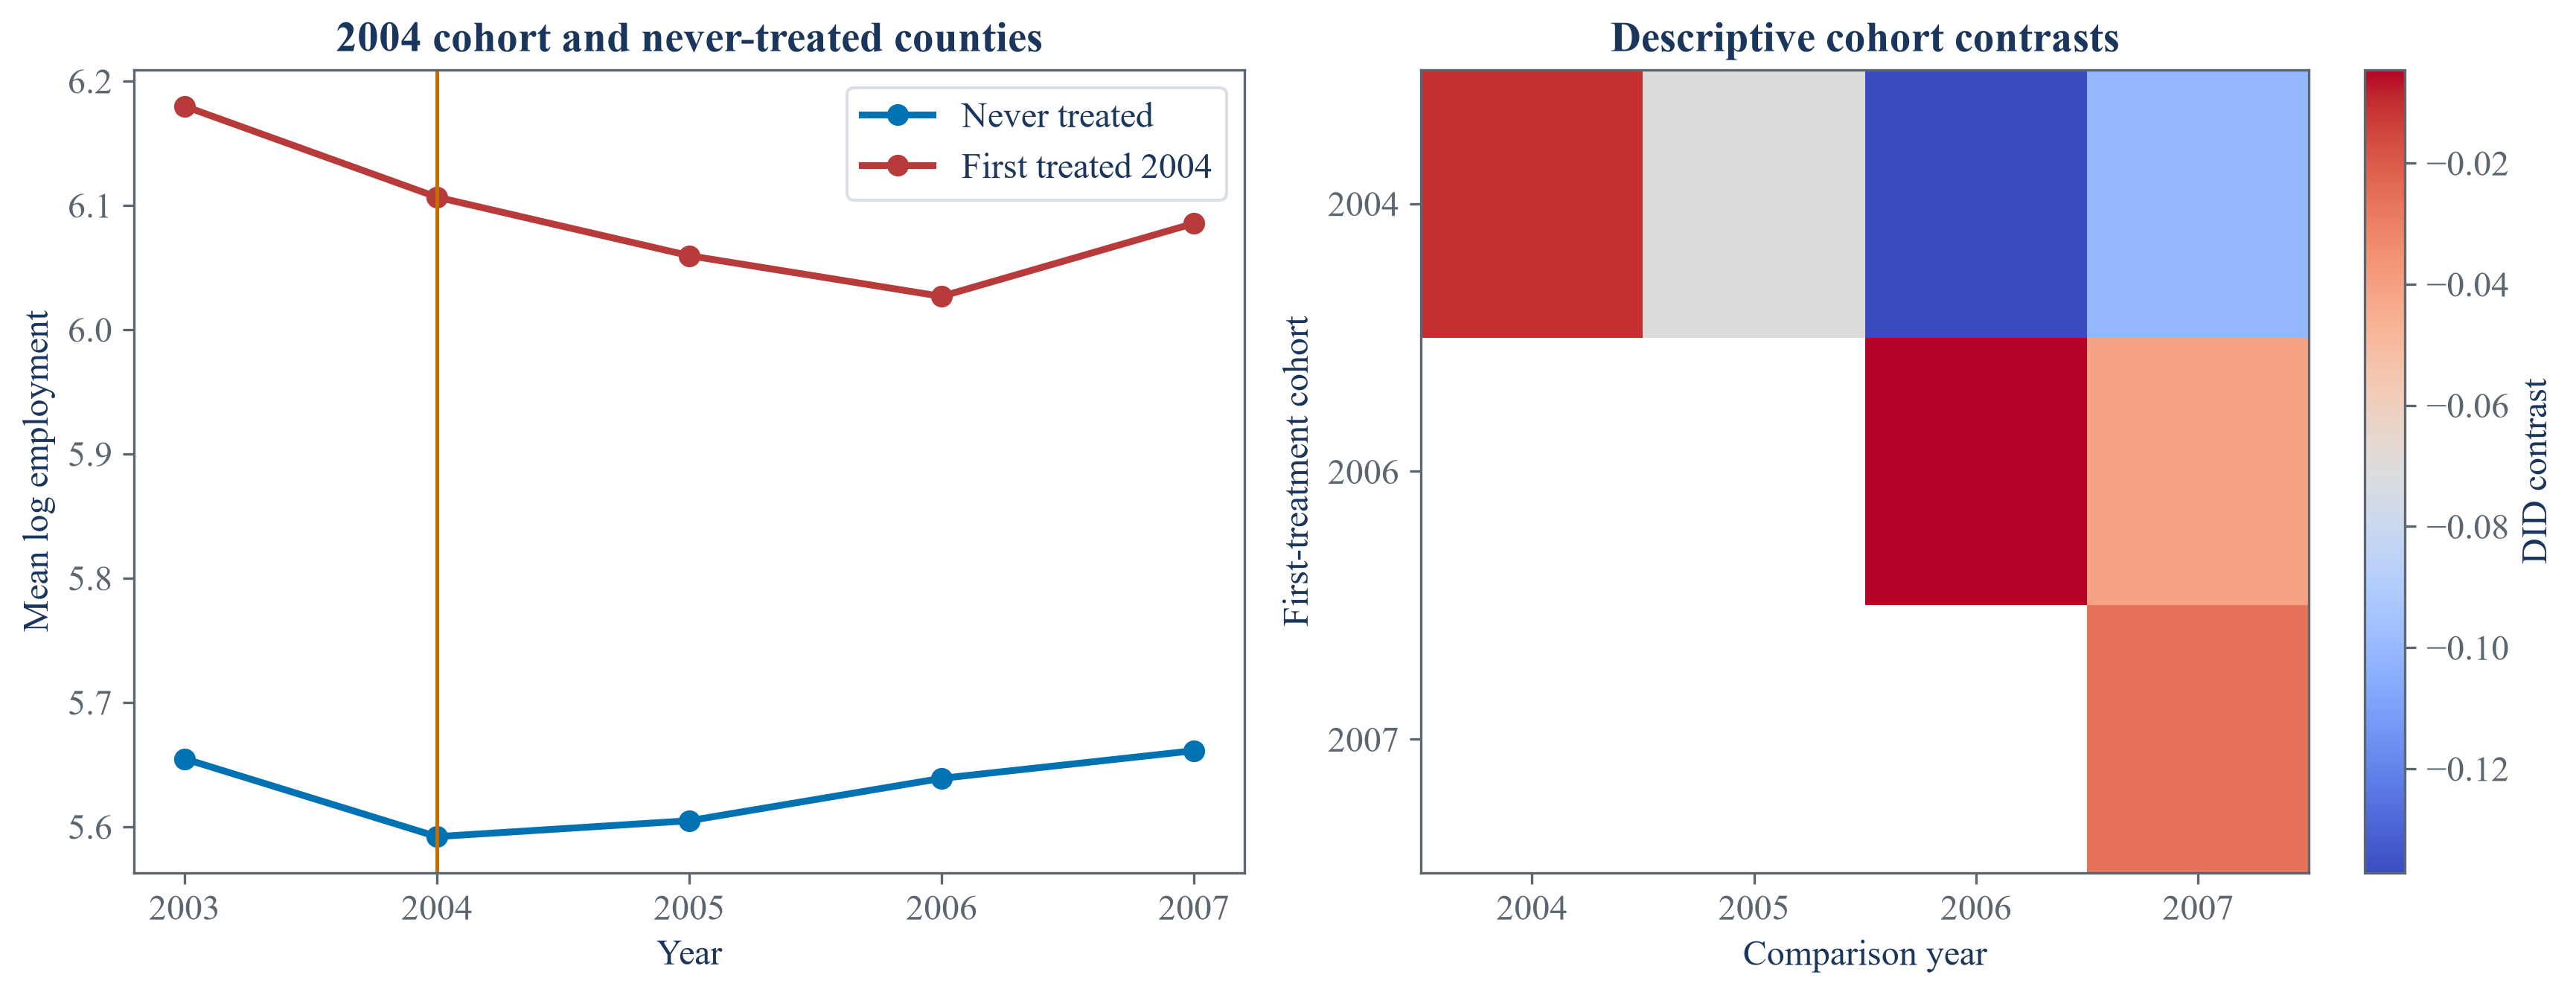

In [2]:
public_rows = []
for cohort in [2004, 2006, 2007]:
    before_year = cohort - 1
    for after_year in range(cohort, 2008):
        treated_before = panel.loc[(panel["first_treat"] == cohort) & (panel["year"] == before_year), "lemp"].mean()
        treated_after = panel.loc[(panel["first_treat"] == cohort) & (panel["year"] == after_year), "lemp"].mean()
        control_before = panel.loc[(panel["first_treat"] == 0) & (panel["year"] == before_year), "lemp"].mean()
        control_after = panel.loc[(panel["first_treat"] == 0) & (panel["year"] == after_year), "lemp"].mean()
        result = difference_in_differences(treated_before, treated_after, control_before, control_after)
        public_rows.append({"First-treatment cohort": cohort, "Base year": before_year, "Comparison year": after_year, "Treated change": result.treated_change, "Never-treated change": result.control_change, "Descriptive DID": result.estimate})
public_did = pd.DataFrame(public_rows)
main_public = public_did[(public_did["First-treatment cohort"] == 2004) & (public_did["Comparison year"] == 2004)].iloc[0]
save_table(public_did, "mpdta_descriptive_did", "Descriptive cohort changes relative to never-treated counties.", "tab:chapter25-mpdta-did")
display(public_did)

public_pretrend_rows = []
for cohort in [2006, 2007]:
    base_year = 2003
    for year in range(2004, cohort):
        treated_base = panel.loc[(panel["first_treat"] == cohort) & (panel["year"] == base_year), "lemp"].mean()
        treated_year = panel.loc[(panel["first_treat"] == cohort) & (panel["year"] == year), "lemp"].mean()
        control_base = panel.loc[(panel["first_treat"] == 0) & (panel["year"] == base_year), "lemp"].mean()
        control_year = panel.loc[(panel["first_treat"] == 0) & (panel["year"] == year), "lemp"].mean()
        placebo = difference_in_differences(treated_base, treated_year, control_base, control_year)
        public_pretrend_rows.append({"Cohort": cohort, "Base year": base_year, "Pre-treatment year": year, "Placebo contrast": placebo.estimate})
public_pretrends = pd.DataFrame(public_pretrend_rows)
save_table(public_pretrends, "mpdta_pretrend_contrasts", "Pre-treatment descriptive contrasts for later-treated cohorts.", "tab:chapter25-mpdta-pretrends")
display(public_pretrends)

figure, axes = plt.subplots(1, 2, figsize=(11.8, 4.6))
selected = cohort_means[cohort_means["first_treat"].isin([0, 2004])]
for cohort, group in selected.groupby("first_treat"):
    label = "Never treated" if cohort == 0 else "First treated 2004"
    color = palette["cyan"] if cohort == 0 else palette["rose"]
    axes[0].plot(group["year"], group["lemp"], marker="o", linewidth=2.2, color=color, label=label)
axes[0].axvline(2004, color=palette["amber"], linewidth=1.2)
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Mean log employment")
axes[0].set_title("2004 cohort and never-treated counties")
year_values = sorted(selected["year"].unique())
axes[0].set_xticks(year_values, [str(year) for year in year_values])
axes[0].legend()
pivot = public_did.pivot(index="First-treatment cohort", columns="Comparison year", values="Descriptive DID")
image_handle = axes[1].imshow(pivot.to_numpy(), cmap="coolwarm", aspect="auto")
axes[1].set_xticks(np.arange(len(pivot.columns)), [str(value) for value in pivot.columns])
axes[1].set_yticks(np.arange(len(pivot.index)), [str(value) for value in pivot.index])
axes[1].set_xlabel("Comparison year")
axes[1].set_ylabel("First-treatment cohort")
axes[1].set_title("Descriptive cohort contrasts")
figure.colorbar(image_handle, ax=axes[1], label="DID contrast")
figure.tight_layout()
save_figure(figure, "mpdta_did_views")

## Testing controlled violations of parallel trends

The parallel-trends condition compares untreated changes across groups:

$$
\mathbb E[Y_{\mathrm{after}}(0)-Y_{\mathrm{before}}(0)\mid G=1]
=\mathbb E[Y_{\mathrm{after}}(0)-Y_{\mathrm{before}}(0)\mid G=0].
$$

Here, $Y_t(0)$ is the untreated potential outcome at time $t$, $G=1$ marks the treated group, $G=0$ marks the comparison group, and equality says their untreated mean changes would have been the same.

,Scenario,Treatment effect,Differential untreated trend,Anticipation,Expected DID,Estimated DID,Error from treatment effect
0,Parallel trends,1.2,0,0,1.2,1.22588,0.02588
1,Nonparallel untreated trends,1.2,0.6,0,1.8,1.776918,0.576918
2,Anticipation before treatment,1.2,0,0.4,0.8,0.789862,-0.410138
3,No treatment effect,0,0,0,0,-0.044193,-0.044193


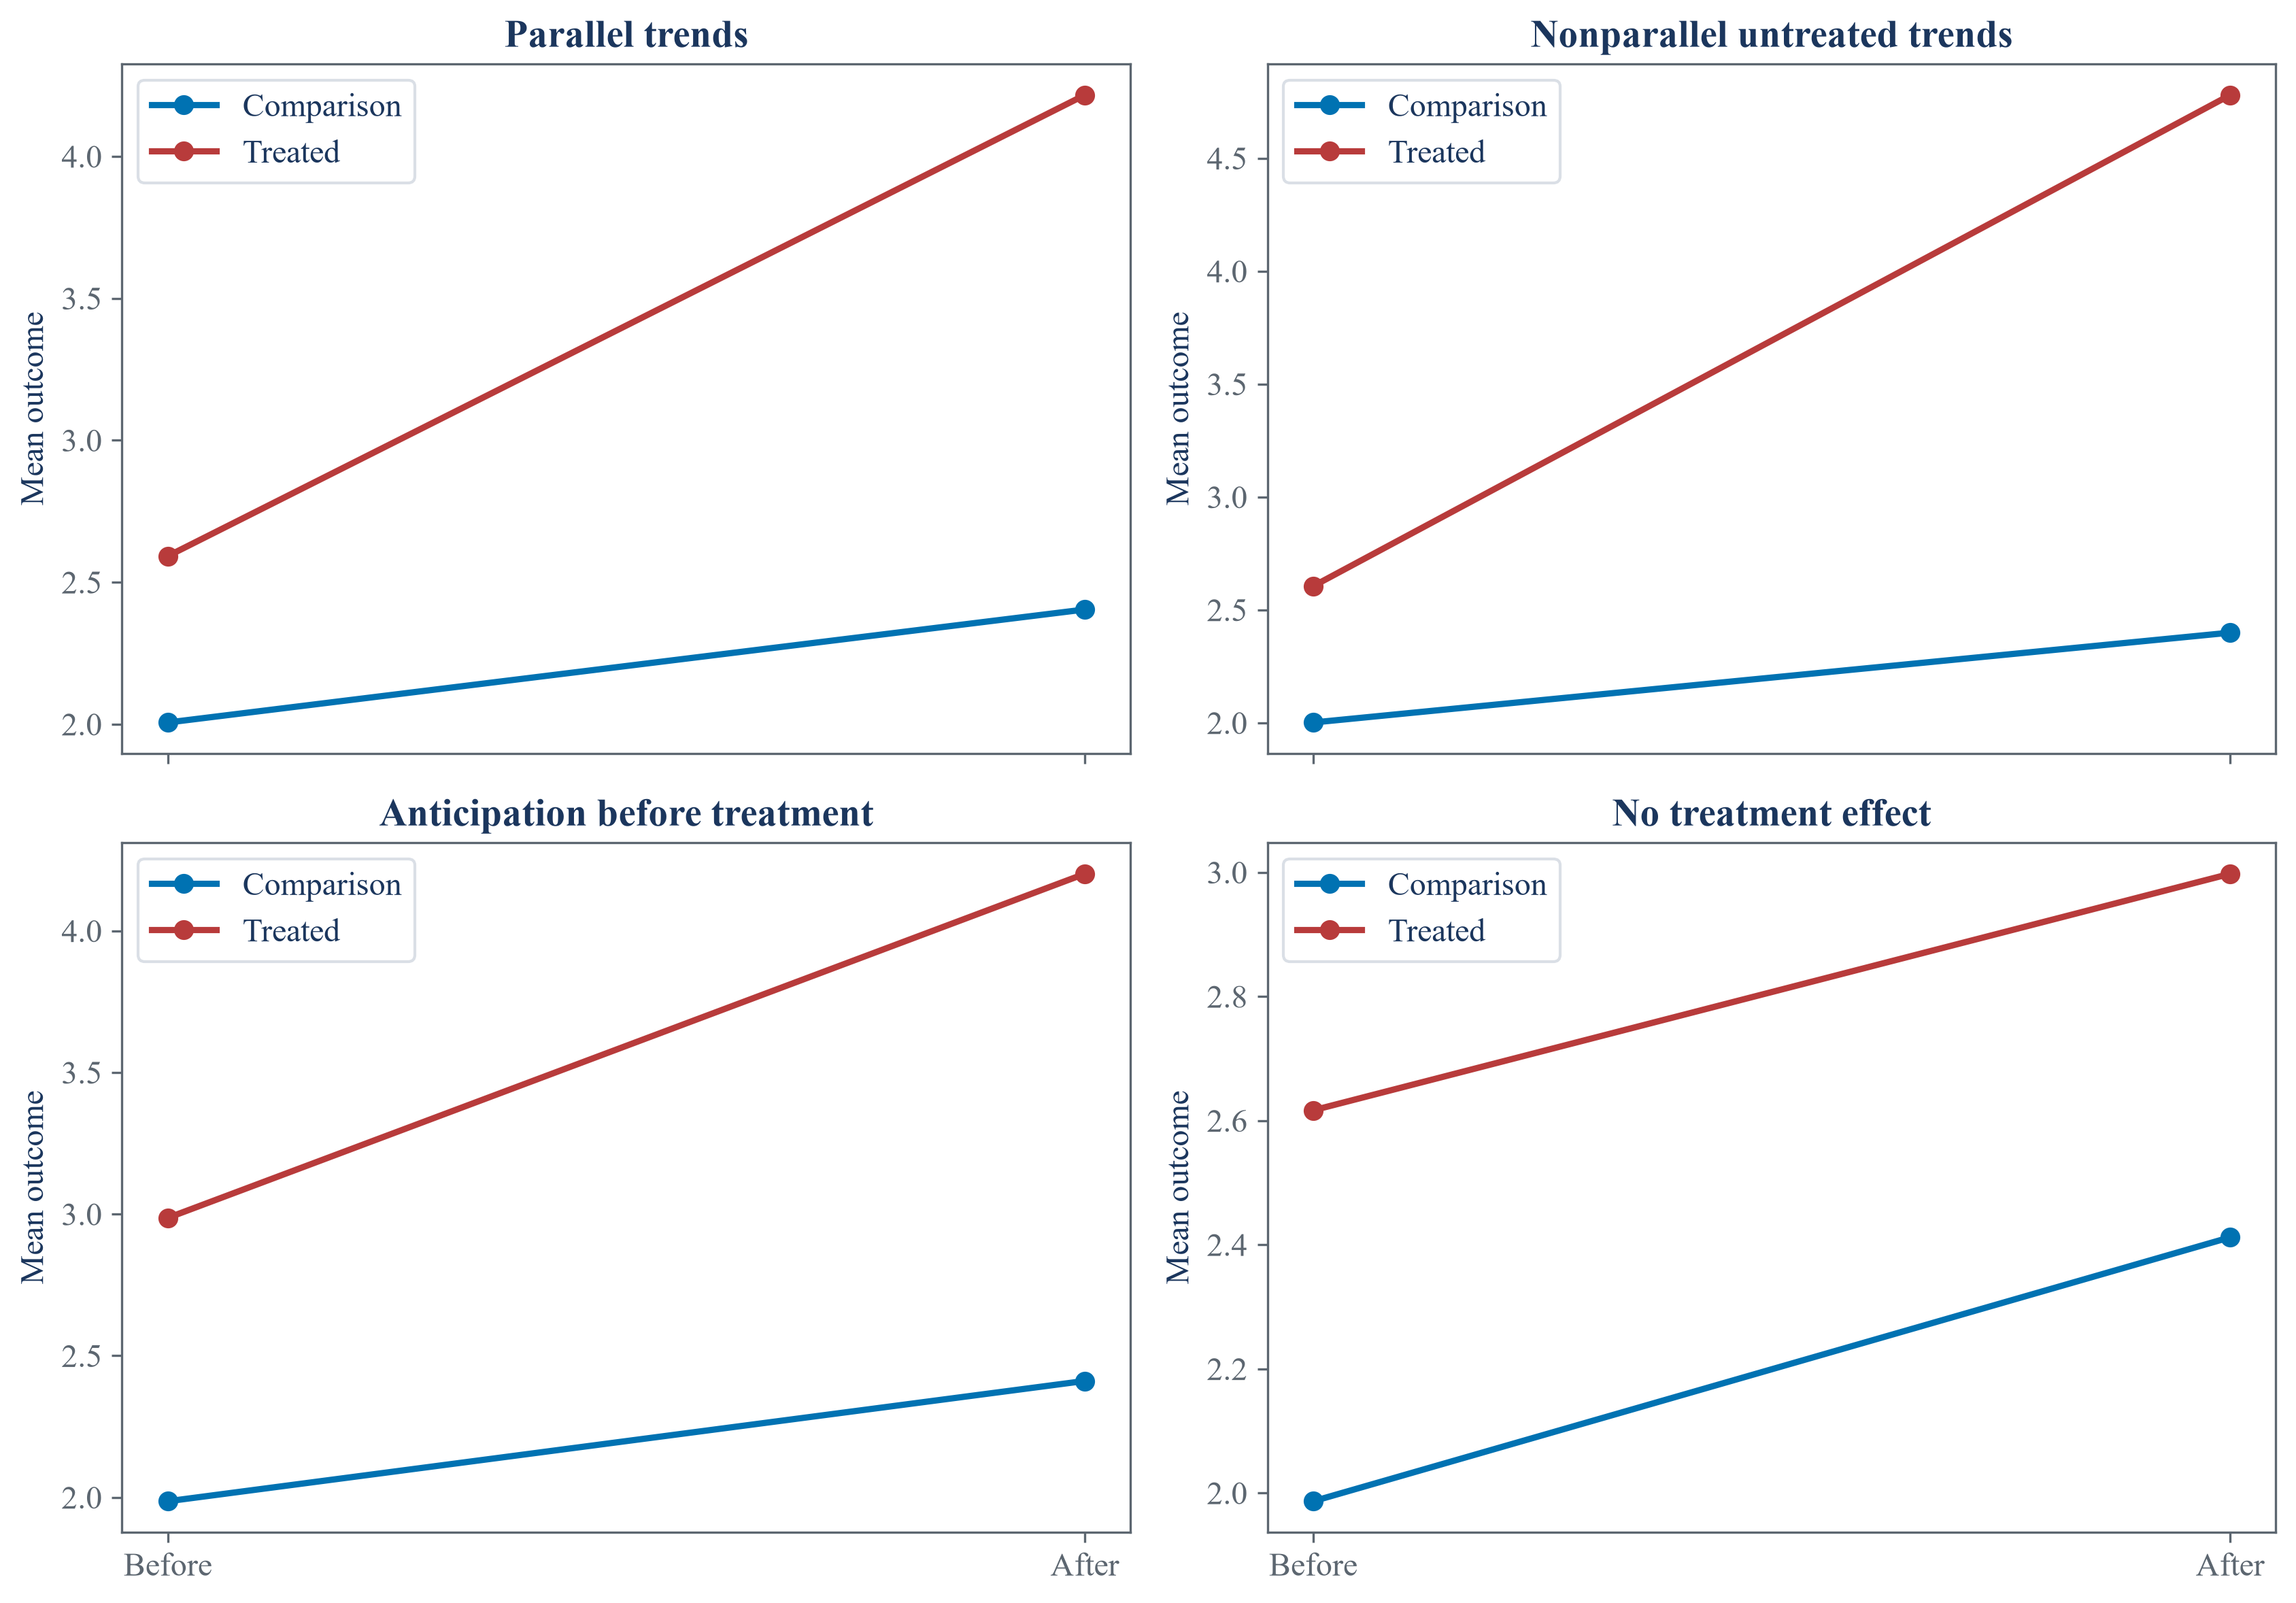

,Scenario,Known treatment effect,Expected DID,Mean estimate,Bias from treatment effect,Root mean squared error from treatment effect,Standard deviation
0,Parallel trends,1.2,1.2,1.200518,0.000518,0.097943,0.09804
1,Nonparallel untreated trends,1.2,1.8,1.802261,0.602261,0.610565,0.100459
2,Anticipation before treatment,1.2,0.8,0.799695,-0.400305,0.413733,0.104656


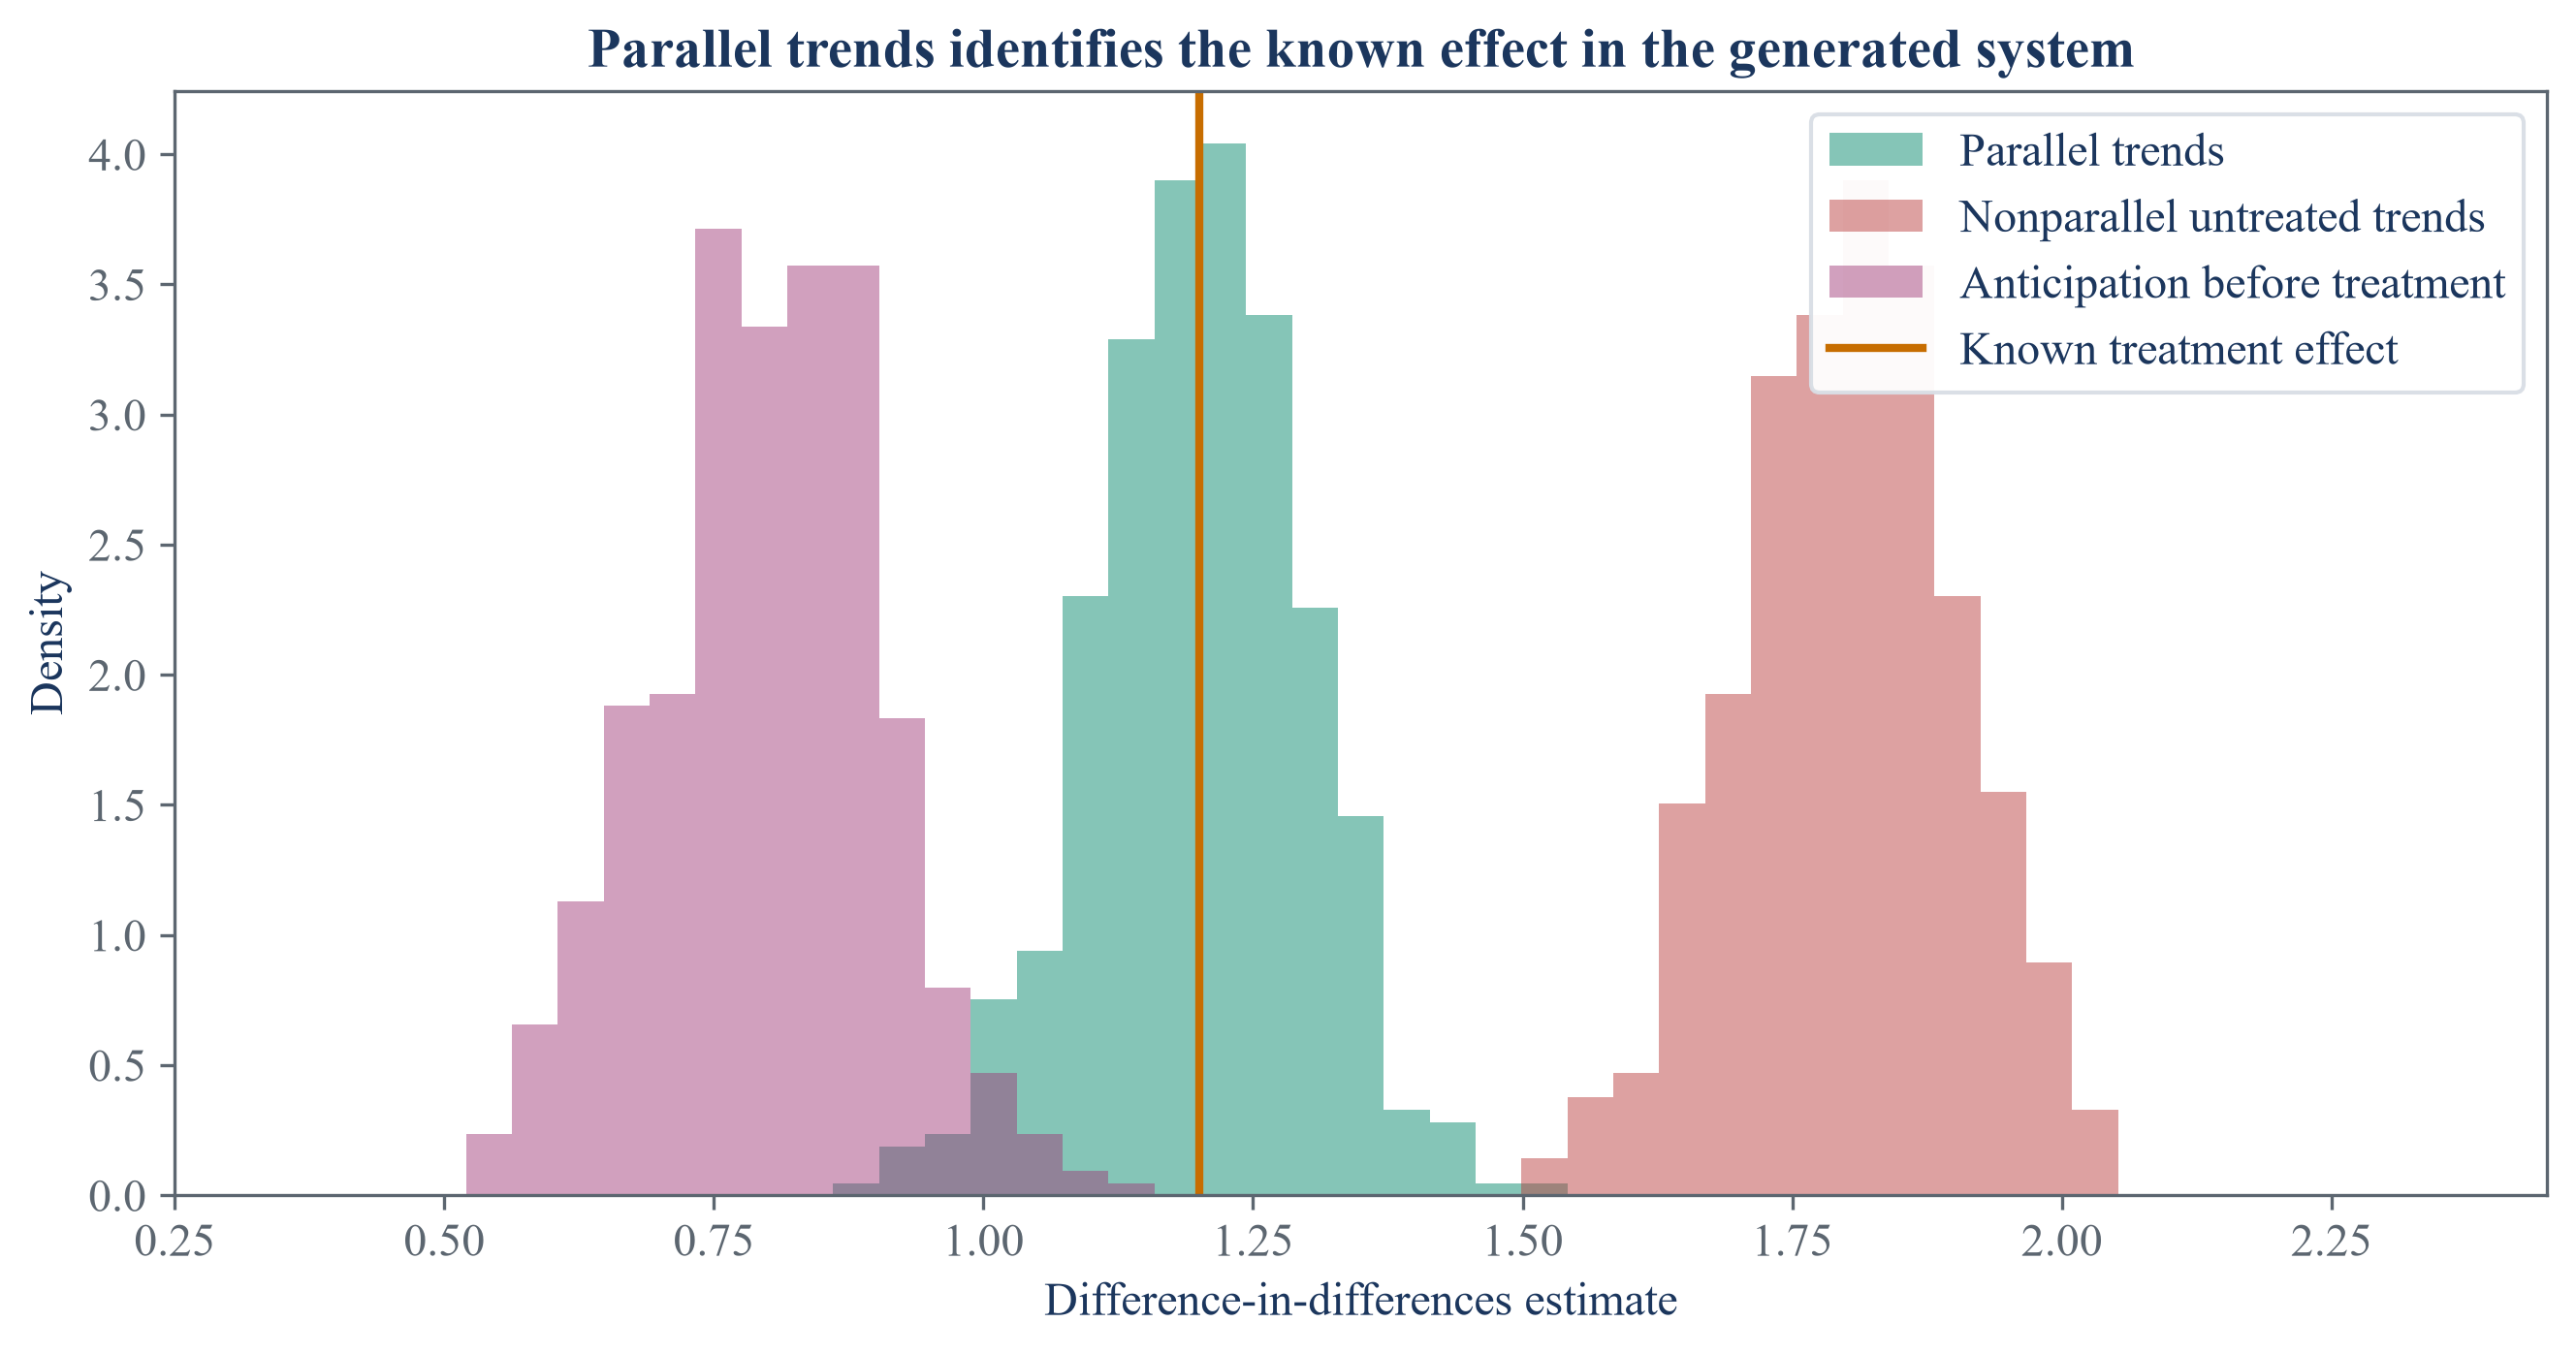

In [3]:
def generated_did(seed, n_per_group, effect, differential_trend=0.0, anticipation=0.0):
    local_rng = np.random.default_rng(seed)
    group = np.repeat([0, 1], n_per_group)
    ability = local_rng.normal(size=2 * n_per_group)
    before_shock = local_rng.normal(scale=0.8, size=2 * n_per_group)
    after_shock = local_rng.normal(scale=0.8, size=2 * n_per_group)
    untreated_before = 2.0 + 0.6 * group + 0.5 * ability + before_shock
    untreated_after = 2.4 + 0.6 * group + differential_trend * group + 0.5 * ability + after_shock
    observed_before = untreated_before + anticipation * group
    observed_after = untreated_after + effect * group
    result = difference_in_differences(observed_before[group == 1].mean(), observed_after[group == 1].mean(), observed_before[group == 0].mean(), observed_after[group == 0].mean())
    return result, pd.DataFrame({"Group": group, "Before": observed_before, "After": observed_after})

scenario_specs = [
    ("Parallel trends", 1.2, 0.0, 0.0),
    ("Nonparallel untreated trends", 1.2, 0.6, 0.0),
    ("Anticipation before treatment", 1.2, 0.0, 0.4),
    ("No treatment effect", 0.0, 0.0, 0.0),
]
scenario_rows = []
scenario_frames = {}
for index, (name, effect, differential, anticipation) in enumerate(scenario_specs):
    result, frame = generated_did(253000 + index, 4000, effect, differential, anticipation)
    scenario_frames[name] = frame
    expected = effect + differential - anticipation
    scenario_rows.append({"Scenario": name, "Treatment effect": effect, "Differential untreated trend": differential, "Anticipation": anticipation, "Expected DID": expected, "Estimated DID": result.estimate, "Error from treatment effect": result.estimate - effect})
generated_did_scenarios = pd.DataFrame(scenario_rows)
save_table(generated_did_scenarios, "generated_did_scenarios", "Difference-in-differences under controlled assumptions and failures.", "tab:chapter25-generated-did")
display(generated_did_scenarios)

figure, axes = plt.subplots(2, 2, figsize=(11.4, 8.0), sharex=True)
for axis, (name, _, _, _) in zip(axes.flat, scenario_specs):
    frame = scenario_frames[name]
    for group_value, label, color in [(0, "Comparison", palette["cyan"]), (1, "Treated", palette["rose"])]:
        means = [frame.loc[frame["Group"] == group_value, "Before"].mean(), frame.loc[frame["Group"] == group_value, "After"].mean()]
        axis.plot([0, 1], means, marker="o", linewidth=2.2, color=color, label=label)
    axis.set_xticks([0, 1], ["Before", "After"])
    axis.set_ylabel("Mean outcome")
    axis.set_title(name)
    axis.legend()
figure.tight_layout()
save_figure(figure, "generated_did_scenario_paths")

repeated_rows = []
repeated_values = {}
for scenario_index, (name, effect, differential, anticipation) in enumerate(scenario_specs[:3]):
    estimates = []
    for repetition in range(500):
        result, _ = generated_did(254000 + scenario_index * 1000 + repetition, 250, effect, differential, anticipation)
        estimates.append(result.estimate)
    estimates = np.asarray(estimates)
    repeated_values[name] = estimates
    repeated_rows.append({"Scenario": name, "Known treatment effect": effect, "Expected DID": effect + differential - anticipation, "Mean estimate": estimates.mean(), "Bias from treatment effect": estimates.mean() - effect, "Root mean squared error from treatment effect": np.sqrt(np.mean((estimates - effect) ** 2)), "Standard deviation": estimates.std(ddof=1)})
did_repeated_summary = pd.DataFrame(repeated_rows)
save_table(did_repeated_summary, "did_repeated_summary", "Repeated difference-in-differences estimates under three scenarios.", "tab:chapter25-did-repeated")
display(did_repeated_summary)

figure, axis = plt.subplots(figsize=(9.0, 4.8))
bins = np.linspace(0.35, 2.35, 48)
for name, color in zip(repeated_values, [palette["green"], palette["rose"], palette["violet"]]):
    axis.hist(repeated_values[name], bins=bins, density=True, alpha=0.48, color=color, label=name)
axis.axvline(1.2, color=palette["amber"], linewidth=2, label="Known treatment effect")
axis.set_xlabel("Difference-in-differences estimate")
axis.set_ylabel("Density")
axis.set_title("Parallel trends identifies the known effect in the generated system")
axis.legend()
figure.tight_layout()
save_figure(figure, "did_repeated_distributions")

## Instrumental-variable covariance ratio

With one valid instrument, the linear effect is represented by the covariance ratio:

$$
\beta_{\mathrm{IV}}
=\frac{\operatorname{Cov}(Z,Y)}{\operatorname{Cov}(Z,X)}.
$$

Here, $Z$ is the instrument, $X$ is treatment, $Y$ is outcome, $\operatorname{Cov}$ denotes covariance, and $\beta_{\mathrm{IV}}$ is the identified linear effect when relevance, exclusion, and outside variation hold.

,Outcome-instrument covariance,Treatment-instrument covariance,Instrumental effect
0,0.9,0.3,3
1,-2,0.5,-4


,Scenario,Relevance,Direct outcome path,Known treatment effect,Mean estimate,Median estimate,Bias,Root mean squared error,Middle 95 percent width
0,Strong valid instrument,1,0,0.8,0.799377,0.803424,-0.000623,0.047939,0.184608
1,Weak valid instrument,0.08,0,0.8,1.248474,0.829259,0.448474,5.24658,3.441895
2,Strong instrument with direct outcome path,1,0.7,0.8,1.501158,1.502575,0.701158,0.702323,0.158456


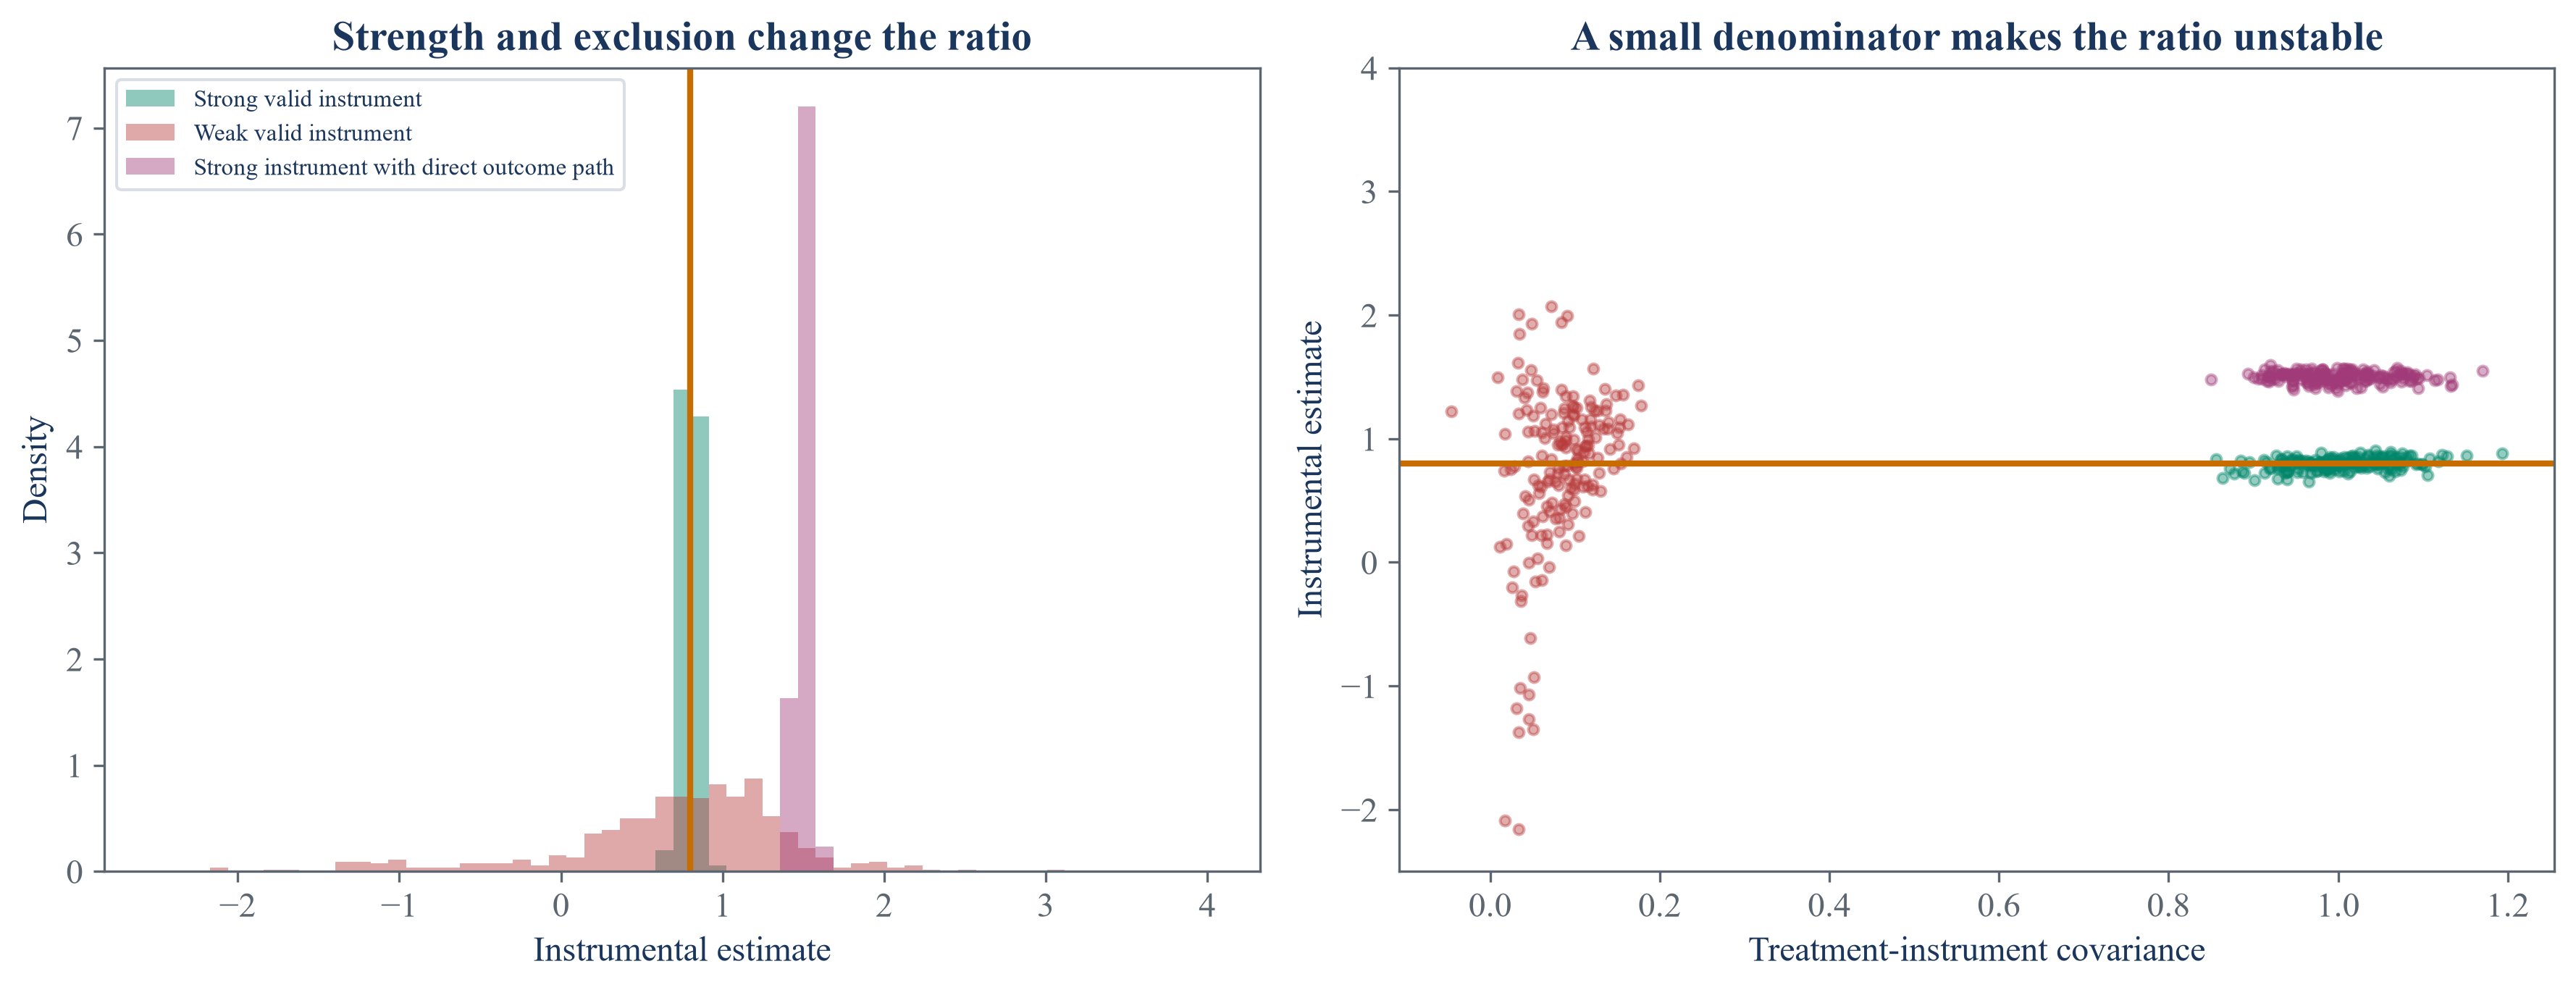

In [4]:
exact_iv = linear_instrumental_variable_effect(0.9, 0.3)
exact_iv_table = pd.DataFrame([
    {"Outcome-instrument covariance": 0.9, "Treatment-instrument covariance": 0.3, "Instrumental effect": exact_iv},
    {"Outcome-instrument covariance": -2.0, "Treatment-instrument covariance": 0.5, "Instrumental effect": linear_instrumental_variable_effect(-2.0, 0.5)},
])
save_table(exact_iv_table, "iv_exact_ratios", "Exact covariance-ratio calculations.", "tab:chapter25-iv-exact")
display(exact_iv_table)

def generated_iv(seed, sample_size, relevance, exclusion_path=0.0):
    local_rng = np.random.default_rng(seed)
    instrument = local_rng.normal(size=sample_size)
    common_cause = local_rng.normal(size=sample_size)
    treatment = relevance * instrument + 0.9 * common_cause + local_rng.normal(size=sample_size)
    outcome = 0.8 * treatment + 1.3 * common_cause + exclusion_path * instrument + local_rng.normal(size=sample_size)
    outcome_covariance = np.cov(instrument, outcome, ddof=1)[0, 1]
    treatment_covariance = np.cov(instrument, treatment, ddof=1)[0, 1]
    estimate = linear_instrumental_variable_effect(outcome_covariance, treatment_covariance)
    return estimate, outcome_covariance, treatment_covariance

iv_specs = [("Strong valid instrument", 1.0, 0.0), ("Weak valid instrument", 0.08, 0.0), ("Strong instrument with direct outcome path", 1.0, 0.7)]
iv_rows = []
iv_estimates = {}
covariance_cloud = []
for scenario_index, (name, relevance, exclusion_path) in enumerate(iv_specs):
    estimates = []
    for repetition in range(500):
        estimate, outcome_covariance, treatment_covariance = generated_iv(255000 + scenario_index * 1000 + repetition, 1200, relevance, exclusion_path)
        estimates.append(estimate)
        if repetition < 180:
            covariance_cloud.append({"Scenario": name, "Treatment-instrument covariance": treatment_covariance, "Instrumental estimate": estimate})
    estimates = np.asarray(estimates)
    iv_estimates[name] = estimates
    iv_rows.append({"Scenario": name, "Relevance": relevance, "Direct outcome path": exclusion_path, "Known treatment effect": 0.8, "Mean estimate": estimates.mean(), "Median estimate": np.median(estimates), "Bias": estimates.mean() - 0.8, "Root mean squared error": np.sqrt(np.mean((estimates - 0.8) ** 2)), "Middle 95 percent width": np.quantile(estimates, 0.975) - np.quantile(estimates, 0.025)})
iv_simulation_summary = pd.DataFrame(iv_rows)
iv_covariance_cloud = pd.DataFrame(covariance_cloud)
save_table(iv_simulation_summary, "iv_simulation_summary", "Instrumental-variable behavior under strength and exclusion changes.", "tab:chapter25-iv-simulation")
save_table(iv_covariance_cloud.groupby("Scenario", as_index=False).agg(Median_denominator=("Treatment-instrument covariance", "median"), Smallest_absolute_denominator=("Treatment-instrument covariance", lambda values: np.min(np.abs(values))), Median_estimate=("Instrumental estimate", "median")), "iv_covariance_summary", "Covariance denominators and estimates in the generated instrument study.", "tab:chapter25-iv-covariance")
display(iv_simulation_summary)

figure, axes = plt.subplots(1, 2, figsize=(12.0, 4.7))
clipped_range = (-2.5, 4.0)
bins = np.linspace(*clipped_range, 60)
for name, color in zip(iv_estimates, [palette["green"], palette["rose"], palette["violet"]]):
    values = iv_estimates[name]
    axes[0].hist(values[(values >= clipped_range[0]) & (values <= clipped_range[1])], bins=bins, density=True, alpha=0.44, color=color, label=name)
axes[0].axvline(0.8, color=palette["amber"], linewidth=2)
axes[0].set_xlabel("Instrumental estimate")
axes[0].set_ylabel("Density")
axes[0].set_title("Strength and exclusion change the ratio")
axes[0].legend(fontsize=8)
for name, color in zip(iv_estimates, [palette["green"], palette["rose"], palette["violet"]]):
    cloud = iv_covariance_cloud[iv_covariance_cloud["Scenario"] == name]
    axes[1].scatter(cloud["Treatment-instrument covariance"], cloud["Instrumental estimate"], s=11, alpha=0.42, color=color, label=name)
axes[1].axhline(0.8, color=palette["amber"], linewidth=2)
axes[1].set_ylim(*clipped_range)
axes[1].set_xlabel("Treatment-instrument covariance")
axes[1].set_ylabel("Instrumental estimate")
axes[1].set_title("A small denominator makes the ratio unstable")
figure.tight_layout()
save_figure(figure, "iv_strength_and_exclusion")

## What the comparisons establish

In [5]:
did_iv_checks = pd.DataFrame([
    contract_result("Nonfinite DID input", lambda: difference_in_differences(0.0, 1.0, 0.0, np.inf), "ValueError"),
    contract_result("Zero IV denominator", lambda: linear_instrumental_variable_effect(1.0, 0.0), "ValueError"),
    contract_result("Nonfinite IV numerator", lambda: linear_instrumental_variable_effect(np.nan, 1.0), "ValueError"),
])
did_iv_summary = pd.DataFrame([
    {"Question": "Does a pre-trend check prove parallel trends?", "Answer": "No"},
    {"Question": "Is a two-period DID enough for every staggered design?", "Answer": "No"},
    {"Question": "Does instrument strength prove exclusion?", "Answer": "No"},
    {"Question": "Why retain generated checks?", "Answer": "They reveal truth and controlled failures"},
    {"Question": "How is the public panel used?", "Answer": "As a descriptive real-data illustration"},
])
save_table(did_iv_checks, "did_iv_input_checks", "Input checks for difference-in-differences and instrumental-variable calculations.", "tab:chapter25-did-iv-input-checks")
save_table(did_iv_summary, "did_iv_section_summary", "Main conclusions from the panel and instrument experiments.", "tab:chapter25-did-iv-summary")
display(did_iv_checks)
display(did_iv_summary)

,Check,Expected result,Observed result,Passed
0,Nonfinite DID input,ValueError,ValueError,True
1,Zero IV denominator,ValueError,ValueError,True
2,Nonfinite IV numerator,ValueError,ValueError,True


,Question,Answer
0,Does a pre-trend check prove parallel trends?,No
1,Is a two-period DID enough for every staggered...,No
2,Does instrument strength prove exclusion?,No
3,Why retain generated checks?,They reveal truth and controlled failures
4,How is the public panel used?,As a descriptive real-data illustration


## Tests

In [6]:
assert panel.shape == (2500, 6)
assert panel["countyreal"].nunique() == 500
assert set(panel["year"].unique()) == {2003, 2004, 2005, 2006, 2007}
assert np.isclose(main_public["Descriptive DID"], -0.01050324622096177)
assert abs(generated_did_scenarios.iloc[0]["Estimated DID"] - 1.2) < 0.08
assert generated_did_scenarios.iloc[1]["Error from treatment effect"] > 0.50
assert generated_did_scenarios.iloc[2]["Error from treatment effect"] < -0.30
assert abs(did_repeated_summary.iloc[0]["Mean estimate"] - 1.2) < 0.04
assert exact_iv == 3.0
assert abs(iv_simulation_summary.iloc[0]["Mean estimate"] - 0.8) < 0.04
assert iv_simulation_summary.iloc[1]["Root mean squared error"] > iv_simulation_summary.iloc[0]["Root mean squared error"] * 3
assert iv_simulation_summary.iloc[2]["Bias"] > 0.60
assert did_iv_checks["Passed"].all()
for stem in ["mpdta_cohort_paths", "mpdta_did_views", "generated_did_scenario_paths", "did_repeated_distributions", "iv_strength_and_exclusion"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["mpdta_inventory", "mpdta_cohort_inventory", "mpdta_cohort_means", "mpdta_descriptive_did", "mpdta_pretrend_contrasts", "generated_did_scenarios", "did_repeated_summary", "iv_exact_ratios", "iv_simulation_summary", "iv_covariance_summary", "did_iv_input_checks", "did_iv_section_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()